In [2]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax


import matplotlib.pyplot as plt
import scipy.io
from scipy.interpolate import griddata

import time
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import mpmath

from NN_class import MLP
from Pwp_class import PiecewiseLinearPolynomials
from minmax_opt_class import pytree_l2_norm, MinMaxOptProb

# Generate key which is used to generate random numbers
key = random.PRNGKey(1)

In [3]:
nu = 0.001

def u0(x):
    return -0.5*(jnp.sign(x) - 1)
def u_exact(t, x):
    return u0(x-0.5*t)

# Boundary at x=-1
def u1(x):
    return 1
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=1
def u2(x):
    return 0
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res_visc(u_quad, u_t, u_x, u_xx, nu):
    return u_t + u_quad * u_x - nu*u_xx
def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x

t = np.linspace(0, 1, num = 101)
x = np.linspace(-1, 1, num = 201)
X, T = np.meshgrid(x, t)
N_u = 400
layers = [2, 50, 50, 50, 50, 1]
hidden_dims = layers[1:-1]
Exact = u_exact(T, X)

X_star = np.hstack((T.flatten()[:,None], X.flatten()[:,None]))
u_star = Exact.flatten()[:,None]

# Domain bounds
lb = X_star.min(0)
ub = X_star.max(0)

In [5]:
seed = 0
mlp = MLP(hidden_dims=hidden_dims, activation=jnp.tanh, lb=lb, ub=ub, seed=seed)
# key = jax.random.PRNGKey(seed)
# params = mlp.init(key, jnp.ones((1, 2)))

# For training, use params as trainable variables
params = mlp.params
net_u = lambda params, tx: mlp(params, tx).squeeze()
u_eval = jit(vmap(net_u, in_axes = (None, 0)))
grad_u = jit(vmap(grad(net_u, argnums=1), in_axes = (None, 0)))
hessian_u = jit(vmap(hessian(net_u, argnums=1), in_axes = (None, 0)))

u0_eval = jit(vmap(u0, in_axes = 0))
u1_eval = jit(vmap(u1, in_axes = 0))
u2_eval = jit(vmap(u2, in_axes = 0))

In [6]:
def net_f(params, tx, nu):
    u = u_eval(params, tx)
    grad_u_tx = grad_u(params, tx)
    u_t, u_x = grad_u_tx[:, 0], grad_u_tx[:, 1]
    u_xx = hessian_u(params, tx)[:, 1, 1]
    f = u_t + u*u_x - nu*u_xx
    return f


In [7]:
optProb = MinMaxOptProb(
    N_t=16,
    N_x=32,
    lr_theta=0.0002,
    N_bc=100,
    N_ic=200,
    t_min=0, t_max=1, x_min=-1, x_max=1,
    hidden_dims=(50, 50, 50, 50),
    seed=0,
    u0=u0, u1=u1, u2=u2,
    nu=0.001,
    res_visc=res_visc,
    res=res,
)
quad_points = optProb.pwp.quad_points
quad_weights = optProb.pwp.quad_weights
X_train = quad_points

xx0 = np.hstack((T[0:1,:].T, X[0:1,:].T)) # (N_x,2) matrix, the initial condition points. Note t comes before x
# uu0 = Exact[0:1,:].T # (N_x, 1) matrix, the initial value
uu0 = u0_eval(X[0,:]).reshape((-1, 1))
xx1 = np.hstack((T[:,0:1], X[:,0:1])) # (N_t,2) matrix, the left bounary points
uu1 = u1_eval(X[:,0:1]).reshape((-1, 1)) # (N_t,1) matrix, the left bounary values
xx2 = np.hstack((T[:,-1:], X[:,-1:])) # (N_t,2) matrix, the right bounary points
uu2 = u2_eval(X[:,-1:]).reshape((-1, 1)) # (N_t,1) matrix, the right bounary values

X_bc = np.vstack([xx0, xx1, xx2])
u_bc = np.vstack([uu0, uu1, uu2]).squeeze()

# opt_init, opt_update, get_params = optimizers.adam(step_size=0.0002)
# opt_state = opt_init(params)

opt_theta = optax.adam(0.0002)
opt_state = opt_theta.init(params)


def loss(params, X_train, nu, u_bc, X_bc):
    res = net_f(params, X_train, nu)
    loss_int = jnp.dot(res**2, quad_weights)
    u_pred_bc = u_eval(params, X_bc)
    loss_ibc = jnp.mean(jnp.square(u_pred_bc-u_bc))
    l = 50*loss_ibc + loss_int
    return l, (loss_int, loss_ibc)

In [8]:
import time

@jit
def train_step(i, params, opt_state, X_train, nu, u_bc, X_bc):
    (val, L_all), g = value_and_grad(loss, argnums=0, has_aux=True)(params, X_train, nu, u_bc, X_bc)
    updates, opt_state = opt_theta.update(g, opt_state)
    params = optax.apply_updates(params, updates)
    return val, params, opt_state
# @jit
# def train_step(i, opt_state, X_train, nu, u_bc, X_bc):
#     params = get_params(opt_state)
#     val, g = value_and_grad(loss, argnums=0)(params, X_train, nu, u_bc, X_bc)
#     optax.apply_updates(params, updates)

start_time = time.perf_counter()
loss_val_his = []
# inv_val_his = []
for i in range(10001):
    # loss_val, opt_state = train_step(i, opt_state, X_train, nu, u_bc, X_bc)
    loss_val, params, opt_state = train_step(i, params, opt_state, X_train, nu, u_bc, X_bc)
    loss_val_his.append(loss_val)
    # inv_val_his.append(inv_val)
    if i % 200 == 0:
        #elapsed = time.time() - start_time
        # params = get_params(opt_state)
        # a_value = params[0]
        print('It: %d, Loss: %.3e' % (i, loss_val))
# params = get_params(opt_state)
loss_val_his = jnp.array(loss_val_his)
# inv_val_his = jnp.array(inv_val_his)
end_time = time.perf_counter()
train_total_time = (end_time - start_time)
print(f"Train total time: {train_total_time:.8f} seconds")

It: 0, Loss: 2.434e+01
It: 200, Loss: 1.941e+00
It: 400, Loss: 1.001e+00
It: 600, Loss: 6.581e-01
It: 800, Loss: 4.095e-01
It: 1000, Loss: 3.166e-01
It: 1200, Loss: 2.651e-01
It: 1400, Loss: 2.387e-01
It: 1600, Loss: 2.199e-01
It: 1800, Loss: 2.041e-01
It: 2000, Loss: 1.871e-01
It: 2200, Loss: 1.512e-01
It: 2400, Loss: 6.281e-02
It: 2600, Loss: 1.871e-02
It: 2800, Loss: 8.444e-03
It: 3000, Loss: 6.089e-03
It: 3200, Loss: 3.384e-03
It: 3400, Loss: 3.051e-03
It: 3600, Loss: 2.227e-03
It: 3800, Loss: 2.191e-03
It: 4000, Loss: 1.850e-03
It: 4200, Loss: 5.544e-03
It: 4400, Loss: 1.623e-03
It: 4600, Loss: 1.354e-03
It: 4800, Loss: 1.183e-03
It: 5000, Loss: 6.222e-03
It: 5200, Loss: 1.952e-03
It: 5400, Loss: 8.678e-04
It: 5600, Loss: 4.254e-03
It: 5800, Loss: 1.557e-03
It: 6000, Loss: 7.492e-04
It: 6200, Loss: 7.487e-04
It: 6400, Loss: 8.266e-04
It: 6600, Loss: 3.370e-03
It: 6800, Loss: 7.679e-04
It: 7000, Loss: 6.070e-04
It: 7200, Loss: 1.452e-03
It: 7400, Loss: 7.317e-04
It: 7600, Loss: 1.1

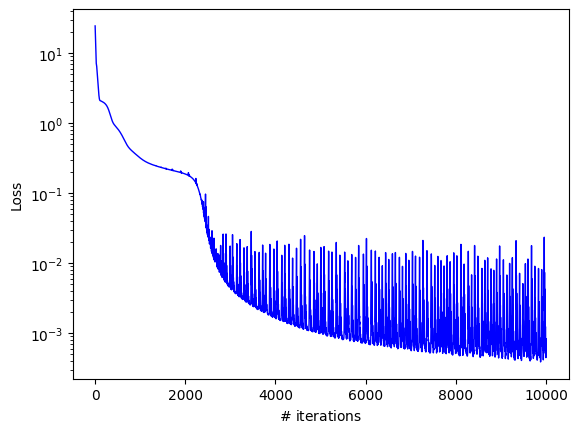

<Figure size 640x480 with 0 Axes>

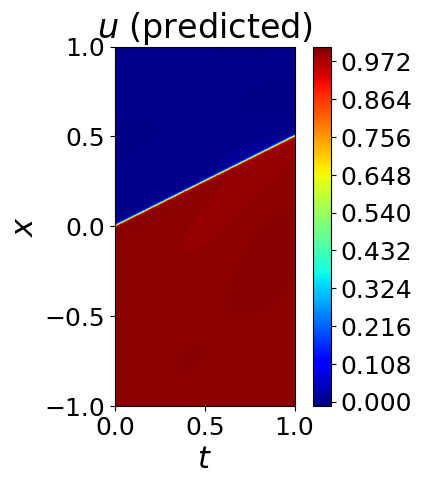

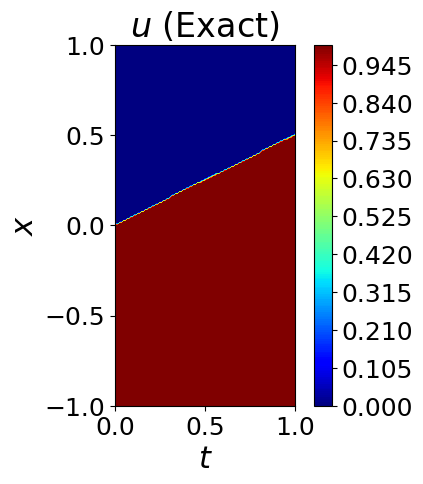

In [11]:
# u_pred = u_eval(params, X_star)
# u_pred = optProb.model.apply({'params': optProb.params}, X_star)
u_pred = optProb.model(params, X_star)
U_pred = griddata(X_star, u_pred.flatten(), (T, X), method='cubic')

plt.plot(loss_val_his,  'b-', linewidth = 1)
plt.xlabel('$\#$ iterations')
plt.ylabel('Loss')
plt.yscale('log')

fig = plt.figure()
# plt.plot(inv_val_his,  'b-', linewidth = 1)
# plt.xlabel('$\#$ iterations')
# plt.ylabel('Invariants_sum')
# plt.yscale('log')

#ax.legend(frameon=False, loc = 'best')
#ax.set_title('$u(x,y)$', fontsize = 10)
#ax.axis('square')
#savefig('./figures/KdV_IC_MSEhistory')

#%%
#fig, ax = newfig(1.0, 1.1)
fig = plt.figure()
gridspec.GridSpec(1,1)

ax = plt.subplot2grid((1,1), (0,0))
levels = np.linspace(-3.4,3.9, 30)
CS_pred1 = ax.contourf(T, X, U_pred, 200, cmap='jet', origin='lower')
cbar = fig.colorbar(CS_pred1)
cbar.ax.tick_params(labelsize=18)
#    ax.set_xlim(0, 1)
#    ax.set_ylim(0, 2)
ax.set_aspect(1)
ax.set_xlabel('$t$', fontsize = 22)
ax.set_ylabel('$x$', fontsize = 22)
ax.set_title('$ u $ (predicted)', fontsize = 24)
ax.tick_params(axis="x", labelsize = 18)
ax.tick_params(axis="y", labelsize = 18)
#plt.plot(xx0[:,0:1],xx0[:,1:2], 'kx',markersize=15)
#plt.plot(xx1[:,0:1],xx1[:,1:2], 'rx',markersize=15)
#plt.plot(xx2[:,0:1],xx2[:,1:2], 'gx',markersize=15)

fig.tight_layout()
fig.set_size_inches(w=4,h=5)
plt.show()
#savefig('./figures/KDV_IntConst')
#%%
#fig, ax = newfig(1.0, 1.1)
fig = plt.figure()
gridspec.GridSpec(1,1)

ax = plt.subplot2grid((1,1), (0,0))
levels = np.linspace(-3.4,3.9, 30)
CS_pred1 = ax.contourf(T, X, np.squeeze(Exact), 200, cmap='jet', origin='lower')
cbar = fig.colorbar(CS_pred1)
cbar.ax.tick_params(labelsize=18)
# ax.set_xlim(0, 1)
# ax.set_ylim(-1, 1)
ax.set_aspect(1)
ax.set_xlabel('$t$', fontsize = 22)
ax.set_ylabel('$x$', fontsize = 22)
ax.set_title('$ u $ (Exact)', fontsize = 24)
ax.tick_params(axis="x", labelsize = 18)
ax.tick_params(axis="y", labelsize = 18)

fig.tight_layout()
fig.set_size_inches(w=4,h=5)
plt.show()
#savefig('./figures/KDV_IntConstEx')

In [31]:
u_pred.shape

(20301,)

In [33]:
u_pred_bc = u_pred = u_eval(params, X_bc)
jnp.mean((u_pred_bc-u_bc)**2)

Array(0.736194, dtype=float32)

In [13]:
val, g = value_and_grad(loss)(params, X_train, nu, u_bc, X_bc)

In [11]:
optProb = MinMaxOptProb(
    N_t=16,
    N_x=32,
    lr_theta=0.0002,
    N_bc=100,
    N_ic=200,
    t_min=0, t_max=1, x_min=-1, x_max=1,
    hidden_dims=(50, 50, 50, 50),
    seed=0,
    u0=u0, u1=vmap_u1, u2=vmap_u2,
    nu=0.001,
    res_visc=res_visc,
    res=res,
)

pre_train_num_iterations = 10001
optProb.pre_train_process(pre_train_num_iterations)


Starting Pre-Train Stage
Iteration 0, lambda_ic: 1.3286751508712769, lambda_bc: 1.1780848503112793, lambda_r: 1.1456272602081299.
Pre-train Iteration 0, Loss_int: 0.11073631, Loss_ibc: 1.36700368
Pre-train Iteration 200, Loss_int: 0.03174655, Loss_ibc: 0.09474830
Pre-train Iteration 400, Loss_int: 0.02100035, Loss_ibc: 0.05913300
Pre-train Iteration 600, Loss_int: 0.01841864, Loss_ibc: 0.04813168
Pre-train Iteration 800, Loss_int: 0.01694109, Loss_ibc: 0.03849501
Iteration 1000, lambda_ic: 1.4057762622833252, lambda_bc: 3.26771879196167, lambda_r: 1.240078330039978.
Pre-train Iteration 1000, Loss_int: 0.01549541, Loss_ibc: 0.03391505
Pre-train Iteration 1200, Loss_int: 0.01388823, Loss_ibc: 0.03203885
Pre-train Iteration 1400, Loss_int: 0.01270633, Loss_ibc: 0.03042397
Pre-train Iteration 1600, Loss_int: 0.01178031, Loss_ibc: 0.02893854
Pre-train Iteration 1800, Loss_int: 0.01068171, Loss_ibc: 0.02747629
Iteration 2000, lambda_ic: 1.4760092496871948, lambda_bc: 10.198872566223145, lam

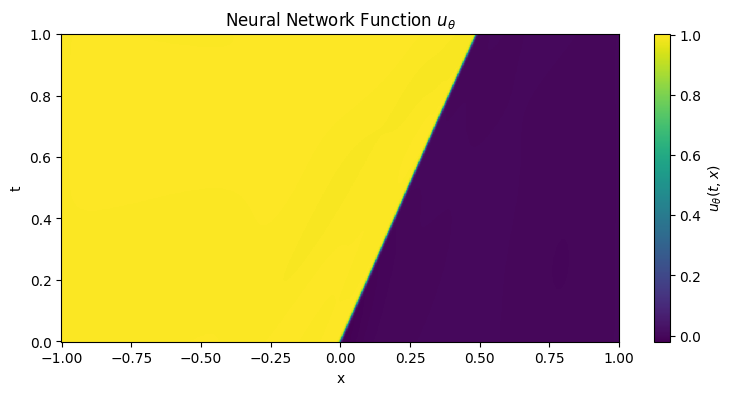

In [12]:
# Function to plot u_theta
def plot_u_theta(model, params, M_t=100, M_x=100, t_min=0.0, t_max=1.0, x_min=0.0, x_max=1.0):
    """
    Plot the neural network function u_theta over a specified domain [t_min, t_max] x [x_min, x_max].

    Args:
        model: Flax model instance representing u_theta.
        params: Parameters (pytree) of the neural network.
        M_t: Number of grid points in the t-direction (default: 100).
        M_x: Number of grid points in the x-direction (default: 100).
        t_min: Minimum value for t (default: 0.0).
        t_max: Maximum value for t (default: 1.0).
        x_min: Minimum value for x (default: 0.0).
        x_max: Maximum value for x (default: 1.0).
    """
    # Create a grid for t and x over the specified ranges
    t_grid = jnp.linspace(t_min, t_max, M_t)
    x_grid = jnp.linspace(x_min, x_max, M_x)
    t, x = jnp.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

    # Flatten the grid for batch evaluation
    tx_points = jnp.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)

    # Evaluate u_theta on the grid points
    u_values = model(params, tx_points)  # Shape: (M_t * M_x, 1)
    # u_values = model.apply(params, tx_points)  # Shape: (M_t * M_x, 1)
    u_values = u_values.reshape(M_t, M_x)  # Reshape to (M_t, M_x)

    # Create the plot
    height = int((t_max - t_min)*4)
    width = int((x_max - x_min)*4 + 1)
    plt.figure(figsize=(width, height))
    plt.pcolormesh(x_grid, t_grid, u_values, shading='nearest', cmap='viridis')
    plt.colorbar(label='$u_\\theta(t, x)$')
    plt.xlabel('x')
    plt.ylabel('t')
    plt.title('Neural Network Function $u_\\theta$')
    plt.show()

plot_u_theta(optProb.model, optProb.params, M_t=500, M_x=1000, t_min=0.0, t_max=1, x_min=-1.0, x_max=1.0)  # Plot after pre-train


In [11]:
from jax.tree_util import tree_leaves
len(tree_leaves(optProb.params))

11

In [14]:
type(optProb.model.params)

list

In [12]:
pytree_l2_norm(params)

Array(10.896193, dtype=float32)

In [ ]:
params